# 2단계 ⓑ — 모델 비교 (21_model_compare)
같은 피처(20 에서 만든 `feat16_stage2.npy`, 32열) · 같은 학습 프로토콜에서 **백본만 바꿔** 전체 성능과 **허브 구간**(수신 계좌 in-degree 50+) 성능을 본다.
06 에서 트리(XGB 0.639) 가 GINe(0.583) 를 넘었으니 2단계의 질문은 "GNN 이 트리보다 뭘 더 주는가, 어느 백본이 허브에서 버티나" 다.

| kind | 모델 | lr | hidden | 양성 가중 | dropout / final | 출처 |
|---|---|---|---|---|---|---|
| `gine` | GINe (1단계와 동일) | 0.0062 | 66 | 6.27 | 0.010 / 0.105 | Multi-GNN 'gin' |
| `gine128` | GINe, hidden 128 | 0.0062 | 128 | 6.27 | 0.010 / 0.105 | 용량 탓인지 확인 |
| `pna` | PNA (mean·max·min·std × 3 스케일러) | 0.0006 | 20 | 7.08 | 0.083 / 0.288 | Multi-GNN 'pna' |
| `gat` | GAT (heads 4) | 0.006 | 64 | 6 | 0.009 / 0.1 | Multi-GNN 'gat' |
| `trans` | TransformerConv (heads 4, = v10 백본) | 0.001 | 64 | 6 | 0.009 / 0.1 | SALT 부록 I |
| `salt_trans` | SALT-Trans (층마다 PNA 통계 + attention 융합) | 0.0012 | 20 | 7 | 0.083 / 0.288 | SALT 부록 I |

- 모델 정의: `bc_models.py` (`MODEL_SETTINGS`, `make_model`). hetero(to / rev_to) 처리·residual 평균·분류 헤드는 모두 1단계 GINe 과 같은 꼴
- 공통: Adam, 배치 2048, 이웃 [100,100], ego ID, port, 가중 CE, 에폭 = 256 배치, 검증 4 에폭마다, patience 8, **검증 AP 로 선택**. 모델별 재튜닝 없음 (튜닝 차이와 모델 차이를 섞지 않기 위해)
- 시드 3 (0, 1, 2). 실행 단위 = (kind, seed) → `results/HI-Small/model_compare/<kind>_s<seed>_*` 에 체크포인트·history·검증/테스트 점수·패턴/차수/컷 표. **끝난 실행은 건너뛰므로** 커널이 죽어도 다시 실행하면 이어진다
- 예상: Small 에폭당 수십 초 → 실행당 30분~1.5시간, 18회 ≈ 1~1.5일

## 0. 작업 준비

In [1]:
import sys, json, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
import bc_lib as B
L = B.L
import torch
import bc_models as M
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); DEVICE

device(type='cuda')

In [2]:
RUN_NAME = 'stage2'
cfg = B.Config(dataset='HI-Small', smoke=False, val_neg_rate=0.05)
OUT_DIR = cfg.out_dir('model_compare')
meta = json.loads((cfg.feat_dir / f'{RUN_NAME}_meta.json').read_text(encoding='utf-8'))     # 20 이 쓴 설정
GNN_FEATURES, TREE_FEATURES, PORT_COLS = meta['gnn_features'], meta['tree_features'], meta['port_cols']
FEAT_PATH, PORTS_PATH = Path(meta['feat_path']), Path(meta['ports_path'])
assert meta['val_neg_rate'] == cfg.val_neg_rate and meta['windows']['train'] == cfg.train_window

MODELS = ['gine', 'gine128', 'pna', 'gat', 'trans', 'salt_trans']
SEEDS  = [0, 1, 2]
pd.DataFrame(M.MODEL_SETTINGS).T.loc[MODELS]

,lr,n_hidden,class_weight,dropout,final_dropout,heads
gine,0.0062,66,"[1.0, 6.27]",0.01,0.105,NaN
gine128,0.0062,128,"[1.0, 6.27]",0.01,0.105,NaN
pna,0.0006,20,"[1.0, 7.08]",0.083,0.288,NaN
gat,0.006,64,"[1.0, 6.0]",0.009,0.1,4
trans,0.001,64,"[1.0, 6.0]",0.009,0.1,4
salt_trans,0.0012,20,"[1.0, 7.0]",0.083,0.288,4


## 1. 데이터 — tx(기본 열 + port) · z-norm 행렬 · 표본 (20 에서 만든 것을 읽기만)

In [3]:
con = L.connect(threads=8, memory='8GB')
currency_codes, format_codes = B.code_tables(con, cfg)
tx = B.load_tx_lowmem(con, cfg, PORTS_PATH)                # tx_base.parquet 이 있으니 바로 읽힘
feat_z = np.load(FEAT_PATH, mmap_mode='r'); assert feat_z.shape == (len(tx), len(GNN_FEATURES)), feat_z.shape
val_df  = pd.read_parquet(meta['samples']['val']); test_df = pd.read_parquet(meta['samples']['test'])
in_degree = pd.read_parquet(meta['samples']['indegree']).set_index('node_id')['in_degree']
con.close()
all_edge_ids = tx['edge_id'].to_numpy()
val_idx = B.rows_of(all_edge_ids, val_df['edge_id'].to_numpy()); test_idx = B.rows_of(all_edge_ids, test_df['edge_id'].to_numpy())
in_train = B.window_mask(tx, cfg.train_window); train_rows = np.flatnonzero(in_train)
del all_edge_ids
print(f'tx {len(tx):,}  피처 {feat_z.shape}  학습 target {len(train_rows):,}  검증 {len(val_df):,}  테스트 {len(test_df):,}')

tx 5,078,336  피처 (5078336, 32)  학습 target 3,248,919  검증 49,261  테스트 862,788


## 2. 그래프 저장소 — 피처 행렬은 GPU float16 (Small 32열 ≈ 0.3GB)

In [4]:
store = B.GraphStore(tx, feat_z, cfg, train_rows=train_rows, val_idx=val_idx, test_idx=test_idx, port_cols=PORT_COLS)
store.features_to_gpu(DEVICE)
del feat_z; gc.collect(); B.trim('(GraphStore 후)')
print(f'GPU 할당 {torch.cuda.memory_allocated() / 1e9:.2f} GB'); store.edge_dim

[05:30:55] 피처 행렬 memmap(기존) (5078336, 32)
[05:30:55] 간선 수 (정방향): 학습까지 3,248,919  검증까지 4,214,440  테스트까지 5,077,228
[05:30:56] 피처 행렬 → cuda float16 (5078336, 32) (0.3GB, 0s)


/home/donghyeon/workspace/money_laundry_ai_/code/binary_classification/bc_lib.py:535: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  out[a:a + chunk] = torch.from_numpy(np.ascontiguousarray(feat[a:a + chunk], dtype=np.float16)).to(device)


RSS 1.4 GB (GraphStore 후)
GPU 할당 0.33 GB


32

In [5]:
# 배치 하나 꺼내 모델 6종의 forward 와 파라미터 수 확인 (학습 전 형상 점검)
batch = next(iter(store.use('train')))
rows = []
for kind in MODELS:
    cfg_m = M.apply_settings(cfg, kind, 0)
    model = B.make_model(kind, store.edge_dim, cfg_m, False, store).to(DEVICE)
    logits, labels = B.forward_batch(model, batch, DEVICE)
    rows.append(dict(kind=kind, n_hidden=cfg_m.n_hidden, lr=cfg_m.lr, pos_weight=cfg_m.class_weight[1], n_params=M.n_params(model), logits=tuple(logits.shape)))
    del model
torch.cuda.empty_cache(); pd.DataFrame(rows).set_index('kind')

RSS 1.4 GB 


/home/donghyeon/workspace/.venv-exp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[05:30:58] 그래프 to 3,248,919 + rev_to 3,248,919 간선 (정렬됨)  0s
RSS 1.8 GB 


/home/donghyeon/workspace/.venv-exp/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(
/home/donghyeon/workspace/.venv-exp/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='min')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


,n_hidden,lr,pos_weight,n_params,logits
kind,,,,,
gine,66,0.0062,6.27,69159,"(2048, 2)"
gine128,128,0.0062,6.27,228065,"(2048, 2)"
pna,20,0.0006,7.08,54477,"(2048, 2)"
gat,64,0.0060,6.00,49441,"(2048, 2)"
trans,64,0.0010,6.00,98593,"(2048, 2)"
salt_trans,20,0.0012,7.00,49837,"(2048, 2)"


## 3. 실행 — (kind, seed) 하나 = 학습 → 검증 점수 저장 → 테스트 점수 저장 → 패턴·차수·컷 표
끝난 실행(`*_results.json` 있음) 은 건너뛴다. 시드 0 을 전 모델 먼저 돌려 중간 비교가 가능하게 (seed-major)

In [ ]:
def run_one(kind, seed):
    name = f'{kind}_s{seed}'
    if (OUT_DIR / f'{name}_results.json').exists():          # 마지막에 쓰는 파일 — 있으면 끝까지 간 실행
        print(f'[{name}] 이미 완료 — 건너뜀'); return
    t0 = time.time(); B.log(f'[{name}] 시작')
    cfg_m = M.apply_settings(cfg, kind, seed); store.cfg = cfg_m; B.seed_all(seed)
    results = {}
    model, hist = B.train_gnn(name, store, cfg_m, val_df, OUT_DIR, DEVICE, results=results, kind=kind)
    # 검증 점수 (22 스태킹용) — 최고 체크포인트 로 다시 추론
    val_score = B.predict_store(model, store, 'val', cfg_m, DEVICE)
    pd.DataFrame(dict(edge_id=val_df.edge_id, y=val_df.y, w=val_df.w, score=val_score)).to_parquet(OUT_DIR / f'{name}_val_scores.parquet', index=False)
    del model; torch.cuda.empty_cache()
    B.test_gnn(name, store, cfg_m, test_df, OUT_DIR, DEVICE, False, results, kind=kind)
    sc = B.load_scores(OUT_DIR / f'{name}_test_scores.parquet')
    B.pattern_recall(sc).to_csv(OUT_DIR / f'{name}_pattern.csv', encoding='utf-8-sig')
    B.degree_stratified(sc, test_df['dst'].to_numpy(), in_degree).to_csv(OUT_DIR / f'{name}_degree.csv', encoding='utf-8-sig')
    B.cut_table(sc).to_csv(OUT_DIR / f'{name}_cuts.csv', encoding='utf-8-sig')
    rec = dict(name=name, seed=seed, family='gnn', settings=M.MODEL_SETTINGS[kind], **results[name])     # results[name] 에 kind 포함 (train_gnn)
    (OUT_DIR / f'{name}_results.json').write_text(json.dumps(rec, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
    B.log(f"[{name}] 끝 {(time.time()-t0)/60:.0f}분  val AP {rec['val']['AP']:.4f}  test AP {rec['test']['AP']:.4f}  best epoch {rec['best_epoch']}")

for seed in SEEDS:
    for kind in MODELS:
        run_one(kind, seed)

[05:31:00] [gine_s0] 시작


epoch   1  loss 0.0303  (18s)


epoch   2  loss 0.0161  (18s)


epoch   3  loss 0.0155  (18s)


RSS 2.2 GB 
[05:32:14] 그래프 to 4,214,440 + rev_to 4,214,440 간선 (정렬됨)  0s
RSS 2.4 GB 
epoch   4  loss 0.0155  AP 0.3759  F1 0.4577  F1@0.5 0.4071  recall@1% 0.6178  (21s)
RSS 2.3 GB 
[05:32:17] 그래프 to 3,248,919 + rev_to 3,248,919 간선 (정렬됨)  0s
RSS 2.6 GB 


epoch   5  loss 0.0149  (19s)


... (806 outputs left out)

epoch  57  loss 0.0125  (27s)


epoch  58  loss 0.0122  (28s)


epoch  59  loss 0.0120  (27s)


gine128_s1 epoch 60:  13%|█▎        | 33/256 [00:03<00:24,  9.27it/s]

## 4. 요약 — 시드 평균 ± 표준편차

In [12]:
def load_results(out_dir, family=None):
    recs = [json.loads(p.read_text(encoding='utf-8')) for p in sorted(out_dir.glob('*_results.json'))]
    rows = []
    for r in recs:
        if family and r.get('family') != family: continue
        rows.append(dict(name=r['name'], kind=r['kind'], seed=r['seed'], val_AP=r['val']['AP'], test_AP=r['test']['AP'], F1=r['test']['F1'], F1_at_0_5=r['test']['F1_at_0.5'],
                         recall_1pct=r['test']['recall_at_1pct'], unmatched_1pct=r['test']['unmatched_recall_at_1pct'],
                         best_epoch=r.get('best_epoch'), train_min=r.get('train_sec', 0) / 60, n_params=r.get('n_params')))
    return pd.DataFrame(rows)

def mean_std(df, by='kind', cols=('val_AP', 'test_AP', 'F1', 'F1_at_0_5', 'recall_1pct', 'unmatched_1pct')):
    g = df.groupby(by)
    out = pd.concat({c: g[c].mean().round(4).astype(str) + ' ± ' + g[c].std().fillna(0).round(4).astype(str) for c in cols}, axis=1)
    out['n_seeds'] = g.size(); return out

runs = load_results(OUT_DIR, 'gnn'); runs.to_csv(OUT_DIR / 'runs_gnn.csv', index=False, encoding='utf-8-sig')
display(runs.round(4))
summary = mean_std(runs).loc[[k for k in MODELS if k in runs.kind.values]]
summary.to_csv(OUT_DIR / 'summary_gnn.csv', encoding='utf-8-sig'); summary

,name,kind,seed,val_AP,test_AP,F1,F1_at_0_5,recall_1pct,unmatched_1pct,best_epoch,train_min,n_params
0,gat_s0,gat,0,0.5090,0.4819,0.5285,0.5255,0.7343,0.3450,28,25.7500,49441
1,gat_s1,gat,1,0.5150,0.4629,0.5169,0.4994,0.7103,0.3181,36,28.8000,49441
2,gat_s2,gat,2,0.5341,0.4967,0.5503,0.5071,0.7280,0.3315,60,38.8333,49441
3,gine128_s0,gine128,0,0.6020,0.5340,0.5844,0.5800,0.7437,0.3935,60,42.8333,228065
4,gine128_s1,gine128,1,0.5888,0.4882,0.5640,0.5562,0.7437,0.4555,92,57.6667,228065
5,gine128_s2,gine128,2,0.5895,0.5609,0.6095,0.6064,0.7071,0.3342,60,42.7167,228065
6,gine_s0,gine,0,0.6135,0.5576,0.6144,0.5974,0.7061,0.3369,104,43.5000,69159
7,gine_s1,gine,1,0.5935,0.5647,0.6058,0.4913,0.7803,0.4420,48,25.1833,69159
8,gine_s2,gine,2,0.5968,0.5763,0.6264,0.6201,0.7741,0.4340,64,30.5167,69159
9,pna_s0,pna,0,0.6364,0.6114,0.6646,0.6321,0.7552,0.3801,76,239.5000,54477


,val_AP,test_AP,F1,F1_at_0_5,recall_1pct,unmatched_1pct,n_seeds
kind,,,,,,,
gine,0.6012 ± 0.0107,0.5662 ± 0.0095,0.6155 ± 0.0104,0.5696 ± 0.0688,0.7535 ± 0.0412,0.4043 ± 0.0585,3
gine128,0.5934 ± 0.0074,0.5277 ± 0.0367,0.586 ± 0.0228,0.5809 ± 0.0251,0.7315 ± 0.0211,0.3944 ± 0.0607,3
pna,0.6316 ± 0.0104,0.6122 ± 0.0085,0.6623 ± 0.0078,0.6369 ± 0.0058,0.7556 ± 0.0099,0.3899 ± 0.0195,3
gat,0.5194 ± 0.0131,0.4805 ± 0.017,0.5319 ± 0.0169,0.5107 ± 0.0134,0.7242 ± 0.0125,0.3315 ± 0.0135,3
trans,0.6473 ± 0.0087,0.6264 ± 0.004,0.6683 ± 0.0058,0.5905 ± 0.0742,0.7727 ± 0.0235,0.4214 ± 0.0586,3
salt_trans,0.6248 ± 0.0128,0.6012 ± 0.0128,0.6551 ± 0.0033,0.6358 ± 0.01,0.75 ± 0.0093,0.3729 ± 0.022,3


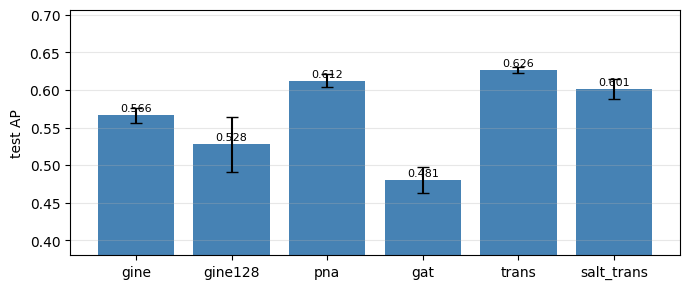

In [13]:
# 테스트 AP — 모델별 평균 ± 표준편차 (가로선 = 06 Large 의 GINe 0.583 / XGB 0.639 는 데이터가 달라 참고만)
g = runs.groupby('kind')['test_AP'].agg(['mean', 'std']).loc[summary.index]
fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(g.index, g['mean'], yerr=g['std'].fillna(0), capsize=4, color='steelblue')
for i, v in enumerate(g['mean']): ax.text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)
ax.set_ylabel('test AP'); ax.set_ylim(max(0, g['mean'].min() - 0.1), min(1, g['mean'].max() + 0.08)); ax.grid(axis='y', alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR / 'test_ap_by_model.png', dpi=120); plt.show()

--- F1 (평균)


bin,[1-4],[5-9],[10-19],[20-49],[50-99],[100+]
kind,,,,,,
gine,0.6741,0.5575,0.5861,0.6383,0.7436,NaN
gine128,0.6666,0.5513,0.5712,0.5905,0.6327,NaN
pna,0.7132,0.6027,0.6280,0.6753,0.7868,NaN
gat,0.5238,0.5054,0.4910,0.5805,0.6450,NaN
trans,0.7444,0.5914,0.6569,0.6748,0.7936,NaN
salt_trans,0.7207,0.5913,0.6187,0.6633,0.7904,NaN


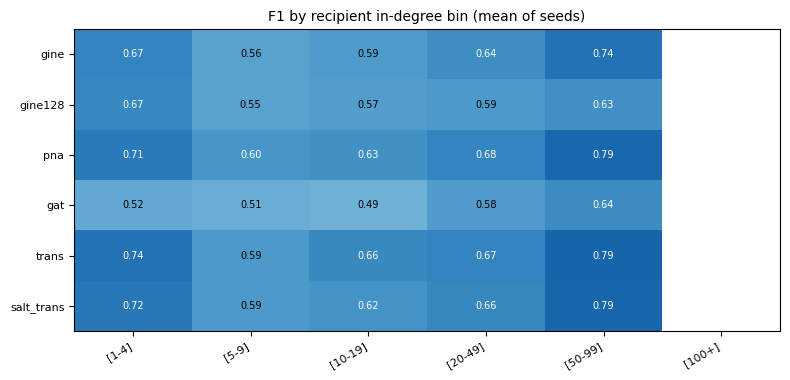

--- AP (평균)


bin,[1-4],[5-9],[10-19],[20-49],[50-99],[100+]
kind,,,,,,
gine,0.6816,0.4937,0.5262,0.5607,0.6731,NaN
gine128,0.6599,0.4784,0.5067,0.4982,0.5728,NaN
pna,0.7209,0.5367,0.5627,0.6026,0.7176,NaN
gat,0.5143,0.4521,0.4298,0.5175,0.5895,NaN
trans,0.7468,0.5422,0.6010,0.6077,0.7286,NaN
salt_trans,0.7234,0.5202,0.5500,0.5873,0.7081,NaN


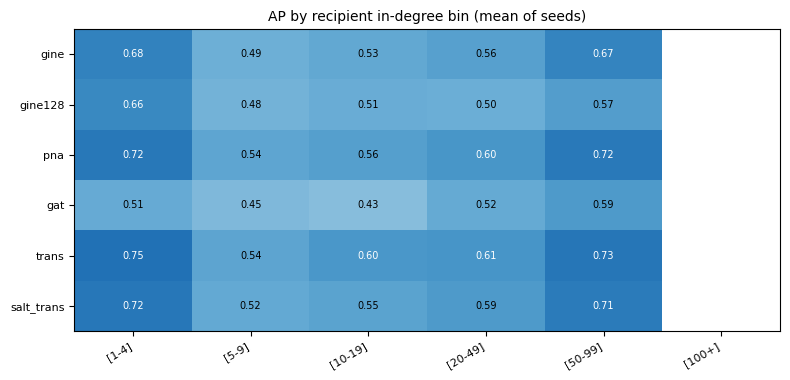

bin,[1-4],[5-9],[10-19],[20-49],[50-99],[100+]
n,40666,41251,136550,590013,52979,1329
n_pos,196,167,195,351,47,0


In [14]:
# 수신 계좌 in-degree 구간별 F1 (최적 임계값) — 모델 × 구간, 시드 평균. SALT 표 2 와 같은 꼴
deg = pd.concat([pd.read_csv(OUT_DIR / f'{r.name}_degree.csv', index_col=0).assign(kind=r.kind, seed=r.seed) for r in runs.itertuples()])
deg.to_csv(OUT_DIR / 'degree_all_runs.csv', encoding='utf-8-sig')
bins = [b for b in deg.index.unique()]
for metric in ('F1', 'AP'):
    m = deg.reset_index().groupby(['kind', 'bin'])[metric].mean().unstack('bin')[bins].loc[summary.index]
    s = deg.reset_index().groupby(['kind', 'bin'])[metric].std().unstack('bin')[bins].loc[summary.index]
    print(f'--- {metric} (평균)'); display(m.round(4))
    (m.round(4).astype(str) + ' ± ' + s.fillna(0).round(4).astype(str)).to_csv(OUT_DIR / f'summary_degree_{metric}.csv', encoding='utf-8-sig')
    B.plot_heatmap(m, title=f'{metric} by recipient in-degree bin (mean of seeds)', path=OUT_DIR / f'degree_{metric}_heatmap.png')
deg.reset_index().groupby('bin')[['n', 'n_pos']].first().loc[bins].T

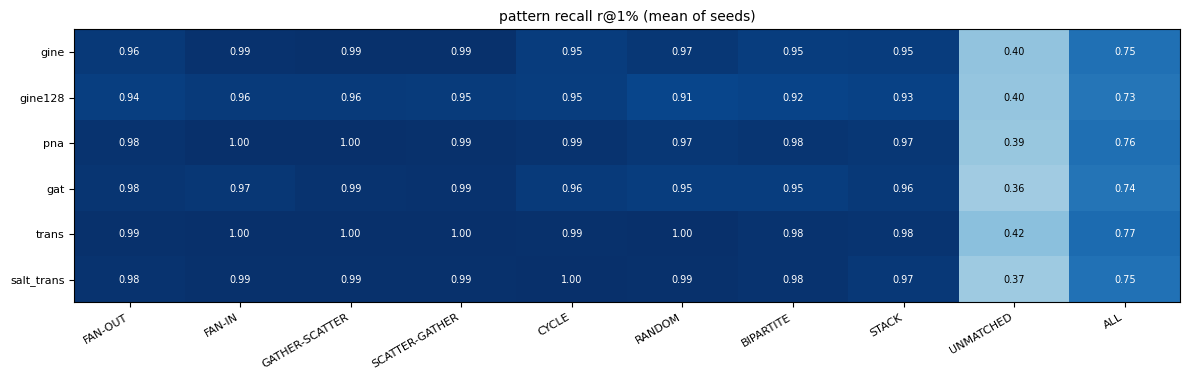

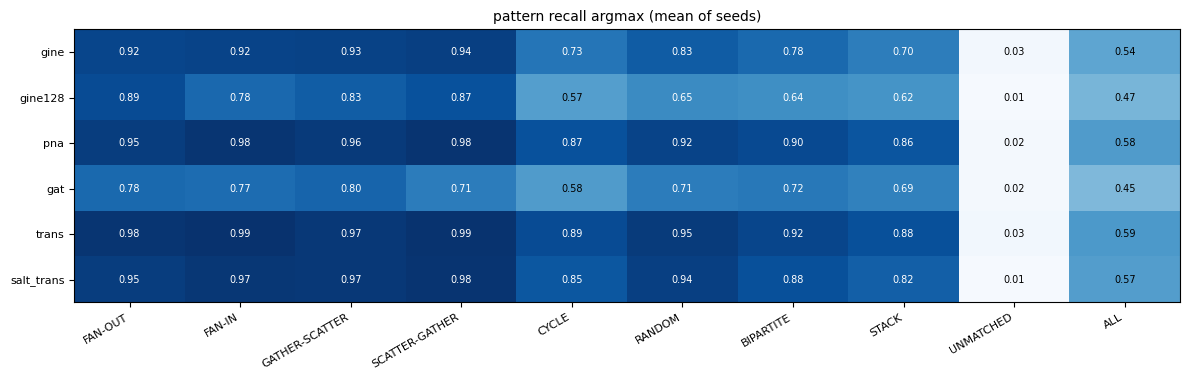

pattern_type
FAN-OUT            65
FAN-IN             57
GATHER-SCATTER    127
SCATTER-GATHER    110
CYCLE              55
RANDOM             43
BIPARTITE          44
STACK              84
UNMATCHED         371
ALL               956
Name: n, dtype: int64

In [15]:
# 패턴 유형별 recall@1% 와 argmax — 모델 × 패턴, 시드 평균
pat = pd.concat([pd.read_csv(OUT_DIR / f'{r.name}_pattern.csv', index_col=0).assign(kind=r.kind, seed=r.seed) for r in runs.itertuples()])
order = [p for p in B.PATTERN_ORDER + ['ALL'] if p in pat.index]
for col in ('r@1%', 'argmax'):
    m = pat.reset_index().groupby(['kind', 'pattern_type'])[col].mean().unstack('pattern_type')[order].loc[summary.index]
    m.round(4).to_csv(OUT_DIR / f'summary_pattern_{col.replace("@", "").replace("%", "pct")}.csv', encoding='utf-8-sig')
    B.plot_heatmap(m, title=f'pattern recall {col} (mean of seeds)', path=OUT_DIR / f'pattern_{col.replace("@", "").replace("%", "pct")}_heatmap.png')
pat.reset_index().groupby('pattern_type')['n'].first().loc[order]

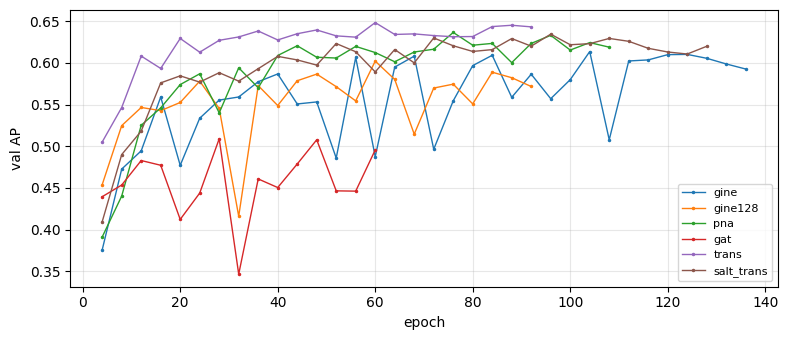

In [16]:
# 학습 곡선 — 모델별 검증 AP (시드 0). 수렴 속도·과적합 비교
fig, ax = plt.subplots(figsize=(8, 3.5))
for kind in summary.index:
    p = OUT_DIR / f'{kind}_s0_history.csv'
    if p.exists():
        h = pd.read_csv(p).dropna(subset=['AP']); ax.plot(h.epoch, h.AP, marker='.', ms=3, lw=1, label=kind)
ax.set_xlabel('epoch'); ax.set_ylabel('val AP'); ax.grid(alpha=.3); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / 'val_curves_s0.png', dpi=120); plt.show()

## 5. 읽는 법
- **전체**: `summary_gnn.csv` 의 test AP 평균 ± 표준편차. 표준편차보다 작은 차이는 모델 차이가 아니다
- **허브**: `summary_degree_F1.csv` 의 `[50-99]`, `[100+]` 열. 전체는 비슷한데 여기서 벌어지면 "허브에서 무너지는 모델" (SALT 논문의 주장이 우리 데이터에서도 맞는지)
- **패턴**: GINe 대비 어느 패턴이 오르고 내리나 — attention 계열(GAT·Trans) 이 FAN 류를, 통계 채널(PNA·SALT) 이 허브 쪽을 살리는지
- **gine128 vs gine**: 오르면 06 의 트리-GNN 차이는 일부 용량 탓. 안 오르면 구조(2홉·이웃 100) 의 한계
- 선정 기준은 22 의 종합표에서 (트리·스태킹 포함): 전체 AP 와 허브 F1 둘 다 상위인 2개 → 3단계 Large